# Proyecto 2: Campo eléctrico de un anillo cargado y trayectorias de partículas

**Integrantes:** ____________________ y ____________________

Dividimos el anillo en cargas puntuales para calcular su campo. Con ese resultado simulamos el movimiento de una carga negativa y de una positiva usando Euler.

In [1]:
%pip -q install numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Parámetros

Usamos los valores de la guía, en unidades reducidas.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi, sqrt
from IPython.display import HTML, display
import json
from html import escape

VISUAL = True
k = 1
Q = 1
R = 1
N0 = 60
m = 1
DT = 0.001

### Campo eléctrico

Sumamos el campo de las N cargas. Las posiciones y los campos se guardan como arreglos con sus componentes x, y, z.

In [3]:
def posiciones_anillo(N):
    angulos = 2*pi*np.arange(N)/N
    return np.column_stack((R*np.cos(angulos), R*np.sin(angulos), np.zeros(N)))


anillos = {N: posiciones_anillo(N) for N in [10, 30, 60, 120]}
anillo = anillos[N0]


def campo_E(r, N=N0):
    if N not in anillos:
        anillos[N] = posiciones_anillo(N)
    d = np.asarray(r) - anillos[N]
    distancias = np.linalg.norm(d, axis=1)
    return k*(Q/N)*np.sum(d/distancias[:, None]**3, axis=0)


def Ez_eje(z):
    return k*Q*z/(R**2 + z**2)**1.5


def V_eje(z):
    return k*Q/sqrt(R**2 + z**2)


def distancia_minima(r):
    return np.min(np.linalg.norm(r-anillo, axis=1))

### Escenas y método de Euler

Las flechas muestran la dirección del campo y tienen longitud 0.3. Calculamos la trayectoria completa antes de mostrarla para que la animación no detenga las demás celdas.

In [4]:
_flechas = None


def escena(titulo="", datos=None, q=1, en_eje=False):
    global _flechas
    if _flechas is None:
        _flechas = []
        puntos = set()
        valores = np.round(np.arange(-2, 2.01, 0.4), 1)
        for a in valores:
            for b in valores:
                puntos.add((a, 0, b))
                puntos.add((0, a, b))
        for punto in sorted(puntos):
            r = np.array(punto)
            if distancia_minima(r) < 0.15:
                continue
            E = campo_E(r)
            norma = np.linalg.norm(E)
            if norma > 0.000000001:
                _flechas.append([r.tolist(), (0.3*E/norma).tolist()])

    contenido = {"titulo": titulo, "anillo": anillo.tolist(),
                 "flechas": _flechas, "datos": datos, "q": q, "eje": en_eje}
    pagina = r"""<!doctype html><html><head><meta charset="utf-8">
<style>body{font:14px sans-serif;margin:8px}button{padding:6px 14px}#estado{margin:8px 0}</style>
</head><body>
<button id="inicio">Iniciar</button><div id="estado"></div>
<div id="glowscript" class="glowscript"></div>
<script>
const datos = __DATOS__;
const estado = document.getElementById('estado');
window.onerror = (mensaje) => { estado.textContent = 'No se pudo mostrar la escena: ' + mensaje; };
async function cargar(url) {
    return new Promise((resolve, reject) => {
        const s = document.createElement('script');
        const limite = setTimeout(() => reject(new Error('No se descargó VPython. Revisa la conexión y vuelve a pulsar Iniciar.')), 15000);
        s.src = url;
        s.onload = () => { clearTimeout(limite); resolve(); };
        s.onerror = () => { clearTimeout(limite); reject(new Error('No se pudo descargar VPython. Revisa la conexión.')); };
        document.head.appendChild(s);
    });
}
let listo = false, vista, bola, curvas;
async function preparar() {
    if (listo) return;
    const base = 'https://www.glowscript.org/';
    if (!window.jQuery) await cargar(base+'lib/jquery/2.1/jquery.min.js');
    if (!jQuery.ui) await cargar(base+'lib/jquery/2.1/jquery-ui.custom.min.js');
    if (!window.canvas) await cargar(base+'package/glow.3.2.min.js');
    window.__context = {glowscript_container: $('#glowscript').removeAttr('id')};
    vista = canvas({width:680, height:420, background:color.white,
        title:datos.titulo, forward:vec(-1,-1,-0.6), range:2.6, autoscale:true});
    for (const p of datos.anillo) sphere({pos:vec(...p), radius:0.04, color:color.red});
    for (const f of datos.flechas) arrow({pos:vec(...f[0]), axis:vec(...f[1]),
        color:color.cyan, shaftwidth:0.015});
    vista.autoscale = true;
    if (datos.datos) {
        const puntos = datos.datos.map(f => f[1]).concat(datos.anillo);
        const minimo = [0,1,2].map(j => Math.min(-2.3, ...puntos.map(p => p[j])));
        const maximo = [0,1,2].map(j => Math.max(2.3, ...puntos.map(p => p[j])));
        const centro = minimo.map((v,j) => (v+maximo[j])/2);
        const radio = Math.max(...puntos.map(p => Math.hypot(...p.map((v,j) => v-centro[j]))));
        vista.center = vec(...centro);
        vista.range = Math.max(3, 1.8*radio);
        vista.autoscale = false;
        bola = sphere({pos:vec(...datos.datos[0][1]), radius:0.05,
            color:datos.q<0 ? color.blue : color.orange, make_trail:true});
        const gz = graph({title:'z(t)', xtitle:'t', ytitle:'z', width:680, height:220, fast:true});
        const ge = graph({title:'Energía', xtitle:'t', ytitle:'E', width:680, height:220, fast:true});
        curvas = [gcurve({graph:gz, color:color.blue}), gcurve({graph:ge, color:color.red, label:'K'})];
        if (datos.eje) curvas.push(gcurve({graph:ge, color:color.green, label:'U'}),
                                  gcurve({graph:ge, color:color.black, label:'E total'}));
    }
    listo = true;
}
document.getElementById('inicio').onclick = async function() {
    this.disabled = true;
    estado.textContent = 'Cargando escena…';
    try {
        await preparar();
        if (datos.datos) {
            bola.clear_trail();
            for (const curva of curvas) curva.data = [];
            estado.textContent = 'Animación en marcha';
            for (let i=0; i<datos.datos.length; i+=5) {
                await rate(500);
                const grupo = datos.datos.slice(i, i+5);
                bola.pos = vec(...grupo[grupo.length-1][1]);
                curvas[0].plot(grupo.map(f => [f[0], f[1][2]]));
                curvas[1].plot(grupo.map(f => [f[0], f[2]]));
                if (datos.eje) {
                    curvas[2].plot(grupo.map(f => [f[0], f[3]]));
                    curvas[3].plot(grupo.map(f => [f[0], f[2]+f[3]]));
                }
            }
            estado.textContent = 'Terminó la animación';
        } else {
            estado.textContent = 'Arrastra con el botón derecho para girar; usa la rueda para acercarte.';
        }
        this.textContent = datos.datos ? 'Repetir' : 'Mostrar';
    } catch (error) {
        estado.textContent = error.message;
    } finally {
        this.disabled = false;
    }
};
</script></body></html>"""
    pagina = pagina.replace('__DATOS__', json.dumps(contenido))
    alto = 1020 if datos is not None else 520
    display(HTML('<details><summary>Ver escena 3D: '+escape(titulo)+
                 '</summary><iframe width="720" height="'+str(alto)+
                 '" style="border:0" srcdoc="'+escape(pagina, quote=True)+'"></iframe></details>'))


def simular(q, r0, v0, tmax, dt=DT, d_min=None, en_eje=False, titulo=""):
    r = np.array(r0, dtype=float)
    v = np.array(v0, dtype=float)
    tiempos, posiciones, K_lista, U_lista = [], [], [], []
    pasos = round(tmax/dt)

    for i in range(pasos + 1):
        t = i*dt
        tiempos.append(t)
        posiciones.append(r.copy())
        K_lista.append(0.5*m*np.dot(v, v))
        if en_eje:
            U_lista.append(q*V_eje(r[2]))

        if i == pasos or (d_min is not None and distancia_minima(r) < d_min):
            break

        a = (q/m)*campo_E(r)
        r = r + v*dt
        v = v + a*dt

    if VISUAL:
        # Se muestran uno de cada diez datos; Euler conserva su paso original.
        indices = list(range(0, len(tiempos), 10))
        if indices[-1] != len(tiempos)-1:
            indices.append(len(tiempos)-1)
        datos = [[tiempos[j], posiciones[j].tolist(), K_lista[j],
                  U_lista[j] if en_eje else 0] for j in indices]
        escena(titulo, datos, q, en_eje)

    return tiempos, posiciones, K_lista, U_lista, r, t

## 1. Campo eléctrico

**1.1.** Comparamos la suma de cargas con la expresión del campo sobre el eje.

In [4]:
print("   z       Ez (suma)       Ez (fórmula)     Error relativo")
for z in [0.5, 1.0, 2.0]:
    E_suma = campo_E(np.array([0, 0, z]))[2]
    E_formula = Ez_eje(z)
    error = abs(E_suma - E_formula)/abs(E_formula)
    print(f"{z:5.1f}     {E_suma:.8f}       {E_formula:.8f}       {error:.2e}")

   z       Ez (suma)       Ez (fórmula)     Error relativo
  0.5     0.35777088       0.35777088       1.09e-15
  1.0     0.35355339       0.35355339       1.10e-15
  2.0     0.17888544       0.17888544       1.09e-15


Los dos cálculos dan el mismo resultado. La diferencia que queda es del orden del redondeo del computador.

**1.2.** Campo en (0.8, 0, 0.1) para distintos valores de N.

In [5]:
campos = []
valores_N = [10, 30, 60, 120]
print(" N        Ex          Ey          Ez")
for N in valores_N:
    E = campo_E(np.array([0.8, 0, 0.1]), N)
    campos.append(E)
    print(f"{N:3d}    {E[0]:10.6f}  {abs(E[1]):10.6f}  {E[2]:10.6f}")

print("\nCambio al aumentar N:")
for i in range(len(campos)-1):
    cambio = np.linalg.norm(campos[i+1] - campos[i])/np.linalg.norm(campos[i+1])
    print(f"{valores_N[i]} a {valores_N[i+1]}: {100*cambio:.6f} %")

 N        Ex          Ey          Ez
 10     -1.553264    0.000000    1.016889
 30     -0.908529    0.000000    0.725356
 60     -0.902034    0.000000    0.722498
120     -0.902028    0.000000    0.722496

Cambio al aumentar N:
10 a 30: 60.863737 %
30 a 60: 0.614037 %
60 a 120: 0.000482 %


**1.3.** Anillo y flechas del campo en los planos x = 0 e y = 0.

In [6]:
if VISUAL:
    escena("Anillo y campo electrico")

Ver escena 3D: Anillo y campo electrico <iframe width="720" height="520" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<style>body{font:14px sans-serif;margin:8px}button{padding:6px 14px}#estado{margin:8px 0}</style>
</head><body>
<button id="inicio">Iniciar</button><div id="estado"></div>
<div id="glowscript" class="glowscript"></div>
<script>
const datos = {"titulo": "Anillo y campo electrico", "anillo": [[1.0, 0.0, 0.0], [0.9945218953682733, 0.10452846326765346, 0.0], [0.9781476007338057, 0.20791169081775931, 0.0], [0.9510565162951535, 0.3090169943749474, 0.0], [0.9135454576426009, 0.40673664307580015, 0.0], [0.8660254037844387, 0.49999999999999994, 0.0], [0.8090169943749475, 0.5877852522924731, 0.0], [0.7431448254773942, 0.6691306063588582, 0.0], [0.6691306063588582, 0.7431448254773941, 0.0], [0.5877852522924731, 0.8090169943749475, 0.0], [0.5000000000000001, 0.8660254037844386, 0.0], [0.4067366430758004, 0.9135454576426009, 0.0], [0.30901699437494745, 0.9510565162951535, 0.0], [0.20791169081775923, 0.9781476007338057, 0.0], [0.10452846326765346, 0.9945218953682733, 0.0], [2.83276944882399e-16, 1.0, 0.0], [-0.10452846326765333, 0.9945218953682734, 0.0], [-0.20791169081775934, 0.9781476007338057, 0.0], [-0.30901699437494734, 0.9510565162951536, 0.0], [-0.40673664307580004, 0.913545457642601, 0.0], [-0.4999999999999998, 0.8660254037844387, 0.0], [-0.587785252292473, 0.8090169943749475, 0.0], [-0.6691306063588579, 0.7431448254773945, 0.0], [-0.743144825477394, 0.6691306063588583, 0.0], [-0.8090169943749473, 0.5877852522924732, 0.0], [-0.8660254037844387, 0.49999999999999994, 0.0], [-0.913545457642601, 0.40673664307580004, 0.0], [-0.9510565162951535, 0.3090169943749475, 0.0], [-0.9781476007338057, 0.20791169081775931, 0.0], [-0.9945218953682734, 0.10452846326765329, 0.0], [-1.0, 5.66553889764798e-16, 0.0], [-0.9945218953682734, -0.10452846326765305, 0.0], [-0.9781476007338057, -0.20791169081775907, 0.0], [-0.9510565162951536, -0.3090169943749473, 0.0], [-0.9135454576426009, -0.4067366430758002, 0.0], [-0.8660254037844388, -0.4999999999999997, 0.0], [-0.8090169943749476, -0.587785252292473, 0.0], [-0.7431448254773942, -0.6691306063588582, 0.0], [-0.6691306063588585, -0.743144825477394, 0.0], [-0.5877852522924732, -0.8090169943749473, 0.0], [-0.5000000000000004, -0.8660254037844384, 0.0], [-0.4067366430758009, -0.9135454576426005, 0.0], [-0.30901699437494756, -0.9510565162951535, 0.0], [-0.2079116908177598, -0.9781476007338056, 0.0], [-0.10452846326765423, -0.9945218953682733, 0.0], [-1.8369701987210297e-16, -1.0, 0.0], [0.10452846326765299, -0.9945218953682734, 0.0], [0.20791169081775943, -0.9781476007338056, 0.0], [0.30901699437494723, -0.9510565162951536, 0.0], [0.40673664307579976, -0.9135454576426011, 0.0], [0.5000000000000001, -0.8660254037844386, 0.0], [0.5877852522924729, -0.8090169943749476, 0.0], [0.6691306063588585, -0.743144825477394, 0.0], [0.7431448254773942, -0.6691306063588581, 0.0], [0.8090169943749473, -0.5877852522924734, 0.0], [0.8660254037844388, -0.49999999999999967, 0.0], [0.913545457642601, -0.40673664307580015, 0.0], [0.9510565162951535, -0.3090169943749476, 0.0], [0.9781476007338057, -0.20791169081775898, 0.0], [0.9945218953682733, -0.10452846326765342, 0.0]], "flechas": [[[-2.0, 0.0, -2.0], [-0.1912947624869286, -4.3450690439143765e-18, -0.23109806110192613]], [[-2.0, 0.0, -1.6], [-0.21104178955260955, -7.625747254305829e-18, -0.21321670446386717]], [[-2.0, 0.0, -1.2], [-0.23431936188465688, -4.317784066310772e-18, -0.18733509187006894]], [[-2.0, 0.0, -0.8], [-0.26117069052978487, -1.130424305057837e-17, -0.14761392349028368]], [[-2.0, 0.0, -0.4], [-0.2875630773746028, -3.9949483844186105e-18, -0.08548377934349988]], [[-2.0, 0.0, -0.0], [-0.3, -1.0298705721115019e-17, 0.0]], [[-2.0, 0.0, 0.4], [-0.2875630773746028, -3.9949483844186105e-18, 0.08548377934349988]], [[-2.0, 0.0, 0.8], [-0.26117069052978487, -1.130424305057837e-17, 0.14761392349028368]], [[-2.0, 0.0, 1.2], [-0.2

**a.** Sobre el eje todas las cargas están a la misma distancia del punto. Además, sus componentes en x e y se cancelan. Como cada carga vale Q/N, al sumar las N contribuciones en z se cancela N y queda la fórmula del anillo continuo.

En (0.8, 0, 0.1) las distancias ya no son iguales y las cargas más cercanas pesan más en la suma. Con pocos puntos la representación del anillo cambia bastante.

Elegimos N = 60 porque, al duplicarlo, el campo cambia solo 0.000482 %. Tomamos como criterio un cambio menor de 0.01 %. Con N = 30 no se cumple: al pasar a 60 cambia cerca de 0.614 %. Esta elección sirve para el punto estudiado; más cerca del anillo habría que revisar otra vez la convergencia.

**b.** En el centro el campo es cero por simetría. Lejos del anillo se parece al de una carga puntual positiva y apunta hacia afuera. Cerca de cada carga, el campo sale de ella y aumenta mucho. Las flechas no muestran ese aumento porque todas tienen la misma longitud.

El campo es perpendicular a las superficies equipotenciales y apunta hacia donde disminuye el potencial: $\vec E=-\nabla V$.

## 2. Oscilación de una carga negativa

Medimos el período entre dos cruces consecutivos de z positivo a negativo. Para estimar el instante del cruce interpolamos entre los dos datos más cercanos.

In [7]:
def periodo(t, z):
    cruces = []
    for i in range(1, len(z)):
        if z[i-1] > 0 and z[i] <= 0:
            cruce = t[i-1] + (t[i]-t[i-1])*z[i-1]/(z[i-1]-z[i])
            cruces.append(cruce)
    periodos = []
    for i in range(len(cruces)-1):
        periodos.append(cruces[i+1]-cruces[i])
    return cruces, periodos


T0 = 2*pi*sqrt(m*R**3/(k*Q*abs(-1)))
print("Período para oscilaciones pequeñas:", round(T0, 4))

Período para oscilaciones pequeñas: 6.2832


**2.1.** Carga en reposo desde (0, 0, 0.2), hasta t = 30.

In [8]:
t1, pos1, K1, U1, rf, tf = simular(-1, np.array([0, 0, 0.2]), np.array([0, 0, 0]), 30, 1e-3,
                                   en_eje=True, titulo="q=-1, z0=0.2")
E1 = [K1[i] + U1[i] for i in range(len(K1))]        # energia total

z1 = [p[2] for p in pos1]
cruces, per = periodo(t1, z1)
print("instantes de cruce:", [round(c, 3) for c in cruces])
print("periodos:", [round(p, 3) for p in per])
print("periodo medio (z0 = 0.2):", round(sum(per)/len(per), 3))

instantes de cruce: [np.float64(1.606), np.float64(8.03), np.float64(14.456), np.float64(20.882), np.float64(27.309)]
periodos: [np.float64(6.424), np.float64(6.425), np.float64(6.426), np.float64(6.427)]
periodo medio (z0 = 0.2): 6.426


Ver escena 3D: q=-1, z0=0.2 <iframe width="720" height="1020" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<style>body{font:14px sans-serif;margin:8px}button{padding:6px 14px}#estado{margin:8px 0}</style>
</head><body>
<button id="inicio">Iniciar</button><div id="estado"></div>
<div id="glowscript" class="glowscript"></div>
<script>
const datos = {"titulo": "q=-1, z0=0.2", "anillo": [[1.0, 0.0, 0.0], [0.9945218953682733, 0.10452846326765346, 0.0], [0.9781476007338057, 0.20791169081775931, 0.0], [0.9510565162951535, 0.3090169943749474, 0.0], [0.9135454576426009, 0.40673664307580015, 0.0], [0.8660254037844387, 0.49999999999999994, 0.0], [0.8090169943749475, 0.5877852522924731, 0.0], [0.7431448254773942, 0.6691306063588582, 0.0], [0.6691306063588582, 0.7431448254773941, 0.0], [0.5877852522924731, 0.8090169943749475, 0.0], [0.5000000000000001, 0.8660254037844386, 0.0], [0.4067366430758004, 0.9135454576426009, 0.0], [0.30901699437494745, 0.9510565162951535, 0.0], [0.20791169081775923, 0.9781476007338057, 0.0], [0.10452846326765346, 0.9945218953682733, 0.0], [2.83276944882399e-16, 1.0, 0.0], [-0.10452846326765333, 0.9945218953682734, 0.0], [-0.20791169081775934, 0.9781476007338057, 0.0], [-0.30901699437494734, 0.9510565162951536, 0.0], [-0.40673664307580004, 0.913545457642601, 0.0], [-0.4999999999999998, 0.8660254037844387, 0.0], [-0.587785252292473, 0.8090169943749475, 0.0], [-0.6691306063588579, 0.7431448254773945, 0.0], [-0.743144825477394, 0.6691306063588583, 0.0], [-0.8090169943749473, 0.5877852522924732, 0.0], [-0.8660254037844387, 0.49999999999999994, 0.0], [-0.913545457642601, 0.40673664307580004, 0.0], [-0.9510565162951535, 0.3090169943749475, 0.0], [-0.9781476007338057, 0.20791169081775931, 0.0], [-0.9945218953682734, 0.10452846326765329, 0.0], [-1.0, 5.66553889764798e-16, 0.0], [-0.9945218953682734, -0.10452846326765305, 0.0], [-0.9781476007338057, -0.20791169081775907, 0.0], [-0.9510565162951536, -0.3090169943749473, 0.0], [-0.9135454576426009, -0.4067366430758002, 0.0], [-0.8660254037844388, -0.4999999999999997, 0.0], [-0.8090169943749476, -0.587785252292473, 0.0], [-0.7431448254773942, -0.6691306063588582, 0.0], [-0.6691306063588585, -0.743144825477394, 0.0], [-0.5877852522924732, -0.8090169943749473, 0.0], [-0.5000000000000004, -0.8660254037844384, 0.0], [-0.4067366430758009, -0.9135454576426005, 0.0], [-0.30901699437494756, -0.9510565162951535, 0.0], [-0.2079116908177598, -0.9781476007338056, 0.0], [-0.10452846326765423, -0.9945218953682733, 0.0], [-1.8369701987210297e-16, -1.0, 0.0], [0.10452846326765299, -0.9945218953682734, 0.0], [0.20791169081775943, -0.9781476007338056, 0.0], [0.30901699437494723, -0.9510565162951536, 0.0], [0.40673664307579976, -0.9135454576426011, 0.0], [0.5000000000000001, -0.8660254037844386, 0.0], [0.5877852522924729, -0.8090169943749476, 0.0], [0.6691306063588585, -0.743144825477394, 0.0], [0.7431448254773942, -0.6691306063588581, 0.0], [0.8090169943749473, -0.5877852522924734, 0.0], [0.8660254037844388, -0.49999999999999967, 0.0], [0.913545457642601, -0.40673664307580015, 0.0], [0.9510565162951535, -0.3090169943749476, 0.0], [0.9781476007338057, -0.20791169081775898, 0.0], [0.9945218953682733, -0.10452846326765342, 0.0]], "flechas": [[[-2.0, 0.0, -2.0], [-0.1912947624869286, -4.3450690439143765e-18, -0.23109806110192613]], [[-2.0, 0.0, -1.6], [-0.21104178955260955, -7.625747254305829e-18, -0.21321670446386717]], [[-2.0, 0.0, -1.2], [-0.23431936188465688, -4.317784066310772e-18, -0.18733509187006894]], [[-2.0, 0.0, -0.8], [-0.26117069052978487, -1.130424305057837e-17, -0.14761392349028368]], [[-2.0, 0.0, -0.4], [-0.2875630773746028, -3.9949483844186105e-18, -0.08548377934349988]], [[-2.0, 0.0, -0.0], [-0.3, -1.0298705721115019e-17, 0.0]], [[-2.0, 0.0, 0.4], [-0.2875630773746028, -3.9949483844186105e-18, 0.08548377934349988]], [[-2.0, 0.0, 0.8], [-0.26117069052978487, -1.130424305057837e-17, 0.14761392349028368]], [[-2.0, 0.0, 1.2], [-0.23431936188465688, -4.31

**2.2.** Repetimos desde (0, 0, 1.5).

In [9]:
t2, pos2, K2, U2, rf, tf = simular(-1, np.array([0, 0, 1.5]), np.array([0, 0, 0]), 30, 1e-3,
                                   en_eje=True, titulo="q=-1, z0=1.5")
E2 = [K2[i] + U2[i] for i in range(len(K2))]

z2 = [p[2] for p in pos2]
cruces, per = periodo(t2, z2)
print("instantes de cruce:", [round(c, 3) for c in cruces])
print("periodos:", [round(p, 3) for p in per])
print("periodo medio (z0 = 1.5):", round(sum(per)/len(per), 3))

instantes de cruce: [np.float64(3.202), np.float64(16.036), np.float64(28.905)]
periodos: [np.float64(12.834), np.float64(12.869)]
periodo medio (z0 = 1.5): 12.851


Ver escena 3D: q=-1, z0=1.5 <iframe width="720" height="1020" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<style>body{font:14px sans-serif;margin:8px}button{padding:6px 14px}#estado{margin:8px 0}</style>
</head><body>
<button id="inicio">Iniciar</button><div id="estado"></div>
<div id="glowscript" class="glowscript"></div>
<script>
const datos = {"titulo": "q=-1, z0=1.5", "anillo": [[1.0, 0.0, 0.0], [0.9945218953682733, 0.10452846326765346, 0.0], [0.9781476007338057, 0.20791169081775931, 0.0], [0.9510565162951535, 0.3090169943749474, 0.0], [0.9135454576426009, 0.40673664307580015, 0.0], [0.8660254037844387, 0.49999999999999994, 0.0], [0.8090169943749475, 0.5877852522924731, 0.0], [0.7431448254773942, 0.6691306063588582, 0.0], [0.6691306063588582, 0.7431448254773941, 0.0], [0.5877852522924731, 0.8090169943749475, 0.0], [0.5000000000000001, 0.8660254037844386, 0.0], [0.4067366430758004, 0.9135454576426009, 0.0], [0.30901699437494745, 0.9510565162951535, 0.0], [0.20791169081775923, 0.9781476007338057, 0.0], [0.10452846326765346, 0.9945218953682733, 0.0], [2.83276944882399e-16, 1.0, 0.0], [-0.10452846326765333, 0.9945218953682734, 0.0], [-0.20791169081775934, 0.9781476007338057, 0.0], [-0.30901699437494734, 0.9510565162951536, 0.0], [-0.40673664307580004, 0.913545457642601, 0.0], [-0.4999999999999998, 0.8660254037844387, 0.0], [-0.587785252292473, 0.8090169943749475, 0.0], [-0.6691306063588579, 0.7431448254773945, 0.0], [-0.743144825477394, 0.6691306063588583, 0.0], [-0.8090169943749473, 0.5877852522924732, 0.0], [-0.8660254037844387, 0.49999999999999994, 0.0], [-0.913545457642601, 0.40673664307580004, 0.0], [-0.9510565162951535, 0.3090169943749475, 0.0], [-0.9781476007338057, 0.20791169081775931, 0.0], [-0.9945218953682734, 0.10452846326765329, 0.0], [-1.0, 5.66553889764798e-16, 0.0], [-0.9945218953682734, -0.10452846326765305, 0.0], [-0.9781476007338057, -0.20791169081775907, 0.0], [-0.9510565162951536, -0.3090169943749473, 0.0], [-0.9135454576426009, -0.4067366430758002, 0.0], [-0.8660254037844388, -0.4999999999999997, 0.0], [-0.8090169943749476, -0.587785252292473, 0.0], [-0.7431448254773942, -0.6691306063588582, 0.0], [-0.6691306063588585, -0.743144825477394, 0.0], [-0.5877852522924732, -0.8090169943749473, 0.0], [-0.5000000000000004, -0.8660254037844384, 0.0], [-0.4067366430758009, -0.9135454576426005, 0.0], [-0.30901699437494756, -0.9510565162951535, 0.0], [-0.2079116908177598, -0.9781476007338056, 0.0], [-0.10452846326765423, -0.9945218953682733, 0.0], [-1.8369701987210297e-16, -1.0, 0.0], [0.10452846326765299, -0.9945218953682734, 0.0], [0.20791169081775943, -0.9781476007338056, 0.0], [0.30901699437494723, -0.9510565162951536, 0.0], [0.40673664307579976, -0.9135454576426011, 0.0], [0.5000000000000001, -0.8660254037844386, 0.0], [0.5877852522924729, -0.8090169943749476, 0.0], [0.6691306063588585, -0.743144825477394, 0.0], [0.7431448254773942, -0.6691306063588581, 0.0], [0.8090169943749473, -0.5877852522924734, 0.0], [0.8660254037844388, -0.49999999999999967, 0.0], [0.913545457642601, -0.40673664307580015, 0.0], [0.9510565162951535, -0.3090169943749476, 0.0], [0.9781476007338057, -0.20791169081775898, 0.0], [0.9945218953682733, -0.10452846326765342, 0.0]], "flechas": [[[-2.0, 0.0, -2.0], [-0.1912947624869286, -4.3450690439143765e-18, -0.23109806110192613]], [[-2.0, 0.0, -1.6], [-0.21104178955260955, -7.625747254305829e-18, -0.21321670446386717]], [[-2.0, 0.0, -1.2], [-0.23431936188465688, -4.317784066310772e-18, -0.18733509187006894]], [[-2.0, 0.0, -0.8], [-0.26117069052978487, -1.130424305057837e-17, -0.14761392349028368]], [[-2.0, 0.0, -0.4], [-0.2875630773746028, -3.9949483844186105e-18, -0.08548377934349988]], [[-2.0, 0.0, -0.0], [-0.3, -1.0298705721115019e-17, 0.0]], [[-2.0, 0.0, 0.4], [-0.2875630773746028, -3.9949483844186105e-18, 0.08548377934349988]], [[-2.0, 0.0, 0.8], [-0.26117069052978487, -1.130424305057837e-17, 0.14761392349028368]], [[-2.0, 0.0, 1.2], [-0.23431936188465688, -4.31

**2.3.** Repetimos con paso 0.01 y comparamos las energías iniciales y finales.

In [10]:
t1b, pos1b, K1b, U1b, rf, tf = simular(-1, np.array([0, 0, 0.2]), np.array([0, 0, 0]), 30, 1e-2,
                                       en_eje=True, titulo="z0=0.2, dt=1e-2")
E1b = [K1b[i] + U1b[i] for i in range(len(K1b))]

t2b, pos2b, K2b, U2b, rf, tf = simular(-1, np.array([0, 0, 1.5]), np.array([0, 0, 0]), 30, 1e-2,
                                       en_eje=True, titulo="z0=1.5, dt=1e-2")
E2b = [K2b[i] + U2b[i] for i in range(len(K2b))]

print("z0 = 0.2, dt = 1e-3: E inicial =", round(E1[0], 6), " E final =", round(E1[-1], 6), " diferencia =", E1[-1] - E1[0])
print("z0 = 0.2, dt = 1e-2: E inicial =", round(E1b[0], 6), " E final =", round(E1b[-1], 6), " diferencia =", E1b[-1] - E1b[0])
print("z0 = 1.5, dt = 1e-3: E inicial =", round(E2[0], 6), " E final =", round(E2[-1], 6), " diferencia =", E2[-1] - E2[0])
print("z0 = 1.5, dt = 1e-2: E inicial =", round(E2b[0], 6), " E final =", round(E2b[-1], 6), " diferencia =", E2b[-1] - E2b[0])

z0 = 0.2, dt = 1e-3: E inicial = -0.980581  E final = -0.980022  diferencia = 0.0005583806533844271
z0 = 0.2, dt = 1e-2: E inicial = -0.980581  E final = -0.974275  diferencia = 0.006305325596887124
z0 = 1.5, dt = 1e-3: E inicial = -0.5547  E final = -0.551827  diferencia = 0.0028736718522001103
z0 = 1.5, dt = 1e-2: E inicial = -0.5547  E final = -0.527069  diferencia = 0.027631239340610403


Ver escena 3D: z0=0.2, dt=1e-2 <iframe width="720" height="1020" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<style>body{font:14px sans-serif;margin:8px}button{padding:6px 14px}#estado{margin:8px 0}</style>
</head><body>
<button id="inicio">Iniciar</button><div id="estado"></div>
<div id="glowscript" class="glowscript"></div>
<script>
const datos = {"titulo": "z0=0.2, dt=1e-2", "anillo": [[1.0, 0.0, 0.0], [0.9945218953682733, 0.10452846326765346, 0.0], [0.9781476007338057, 0.20791169081775931, 0.0], [0.9510565162951535, 0.3090169943749474, 0.0], [0.9135454576426009, 0.40673664307580015, 0.0], [0.8660254037844387, 0.49999999999999994, 0.0], [0.8090169943749475, 0.5877852522924731, 0.0], [0.7431448254773942, 0.6691306063588582, 0.0], [0.6691306063588582, 0.7431448254773941, 0.0], [0.5877852522924731, 0.8090169943749475, 0.0], [0.5000000000000001, 0.8660254037844386, 0.0], [0.4067366430758004, 0.9135454576426009, 0.0], [0.30901699437494745, 0.9510565162951535, 0.0], [0.20791169081775923, 0.9781476007338057, 0.0], [0.10452846326765346, 0.9945218953682733, 0.0], [2.83276944882399e-16, 1.0, 0.0], [-0.10452846326765333, 0.9945218953682734, 0.0], [-0.20791169081775934, 0.9781476007338057, 0.0], [-0.30901699437494734, 0.9510565162951536, 0.0], [-0.40673664307580004, 0.913545457642601, 0.0], [-0.4999999999999998, 0.8660254037844387, 0.0], [-0.587785252292473, 0.8090169943749475, 0.0], [-0.6691306063588579, 0.7431448254773945, 0.0], [-0.743144825477394, 0.6691306063588583, 0.0], [-0.8090169943749473, 0.5877852522924732, 0.0], [-0.8660254037844387, 0.49999999999999994, 0.0], [-0.913545457642601, 0.40673664307580004, 0.0], [-0.9510565162951535, 0.3090169943749475, 0.0], [-0.9781476007338057, 0.20791169081775931, 0.0], [-0.9945218953682734, 0.10452846326765329, 0.0], [-1.0, 5.66553889764798e-16, 0.0], [-0.9945218953682734, -0.10452846326765305, 0.0], [-0.9781476007338057, -0.20791169081775907, 0.0], [-0.9510565162951536, -0.3090169943749473, 0.0], [-0.9135454576426009, -0.4067366430758002, 0.0], [-0.8660254037844388, -0.4999999999999997, 0.0], [-0.8090169943749476, -0.587785252292473, 0.0], [-0.7431448254773942, -0.6691306063588582, 0.0], [-0.6691306063588585, -0.743144825477394, 0.0], [-0.5877852522924732, -0.8090169943749473, 0.0], [-0.5000000000000004, -0.8660254037844384, 0.0], [-0.4067366430758009, -0.9135454576426005, 0.0], [-0.30901699437494756, -0.9510565162951535, 0.0], [-0.2079116908177598, -0.9781476007338056, 0.0], [-0.10452846326765423, -0.9945218953682733, 0.0], [-1.8369701987210297e-16, -1.0, 0.0], [0.10452846326765299, -0.9945218953682734, 0.0], [0.20791169081775943, -0.9781476007338056, 0.0], [0.30901699437494723, -0.9510565162951536, 0.0], [0.40673664307579976, -0.9135454576426011, 0.0], [0.5000000000000001, -0.8660254037844386, 0.0], [0.5877852522924729, -0.8090169943749476, 0.0], [0.6691306063588585, -0.743144825477394, 0.0], [0.7431448254773942, -0.6691306063588581, 0.0], [0.8090169943749473, -0.5877852522924734, 0.0], [0.8660254037844388, -0.49999999999999967, 0.0], [0.913545457642601, -0.40673664307580015, 0.0], [0.9510565162951535, -0.3090169943749476, 0.0], [0.9781476007338057, -0.20791169081775898, 0.0], [0.9945218953682733, -0.10452846326765342, 0.0]], "flechas": [[[-2.0, 0.0, -2.0], [-0.1912947624869286, -4.3450690439143765e-18, -0.23109806110192613]], [[-2.0, 0.0, -1.6], [-0.21104178955260955, -7.625747254305829e-18, -0.21321670446386717]], [[-2.0, 0.0, -1.2], [-0.23431936188465688, -4.317784066310772e-18, -0.18733509187006894]], [[-2.0, 0.0, -0.8], [-0.26117069052978487, -1.130424305057837e-17, -0.14761392349028368]], [[-2.0, 0.0, -0.4], [-0.2875630773746028, -3.9949483844186105e-18, -0.08548377934349988]], [[-2.0, 0.0, -0.0], [-0.3, -1.0298705721115019e-17, 0.0]], [[-2.0, 0.0, 0.4], [-0.2875630773746028, -3.9949483844186105e-18, 0.08548377934349988]], [[-2.0, 0.0, 0.8], [-0.26117069052978487, -1.130424305057837e-17, 0.14761392349028368]], [[-2.0, 0.0, 1.2], [-0.23431936188465688,

Ver escena 3D: z0=1.5, dt=1e-2 <iframe width="720" height="1020" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<style>body{font:14px sans-serif;margin:8px}button{padding:6px 14px}#estado{margin:8px 0}</style>
</head><body>
<button id="inicio">Iniciar</button><div id="estado"></div>
<div id="glowscript" class="glowscript"></div>
<script>
const datos = {"titulo": "z0=1.5, dt=1e-2", "anillo": [[1.0, 0.0, 0.0], [0.9945218953682733, 0.10452846326765346, 0.0], [0.9781476007338057, 0.20791169081775931, 0.0], [0.9510565162951535, 0.3090169943749474, 0.0], [0.9135454576426009, 0.40673664307580015, 0.0], [0.8660254037844387, 0.49999999999999994, 0.0], [0.8090169943749475, 0.5877852522924731, 0.0], [0.7431448254773942, 0.6691306063588582, 0.0], [0.6691306063588582, 0.7431448254773941, 0.0], [0.5877852522924731, 0.8090169943749475, 0.0], [0.5000000000000001, 0.8660254037844386, 0.0], [0.4067366430758004, 0.9135454576426009, 0.0], [0.30901699437494745, 0.9510565162951535, 0.0], [0.20791169081775923, 0.9781476007338057, 0.0], [0.10452846326765346, 0.9945218953682733, 0.0], [2.83276944882399e-16, 1.0, 0.0], [-0.10452846326765333, 0.9945218953682734, 0.0], [-0.20791169081775934, 0.9781476007338057, 0.0], [-0.30901699437494734, 0.9510565162951536, 0.0], [-0.40673664307580004, 0.913545457642601, 0.0], [-0.4999999999999998, 0.8660254037844387, 0.0], [-0.587785252292473, 0.8090169943749475, 0.0], [-0.6691306063588579, 0.7431448254773945, 0.0], [-0.743144825477394, 0.6691306063588583, 0.0], [-0.8090169943749473, 0.5877852522924732, 0.0], [-0.8660254037844387, 0.49999999999999994, 0.0], [-0.913545457642601, 0.40673664307580004, 0.0], [-0.9510565162951535, 0.3090169943749475, 0.0], [-0.9781476007338057, 0.20791169081775931, 0.0], [-0.9945218953682734, 0.10452846326765329, 0.0], [-1.0, 5.66553889764798e-16, 0.0], [-0.9945218953682734, -0.10452846326765305, 0.0], [-0.9781476007338057, -0.20791169081775907, 0.0], [-0.9510565162951536, -0.3090169943749473, 0.0], [-0.9135454576426009, -0.4067366430758002, 0.0], [-0.8660254037844388, -0.4999999999999997, 0.0], [-0.8090169943749476, -0.587785252292473, 0.0], [-0.7431448254773942, -0.6691306063588582, 0.0], [-0.6691306063588585, -0.743144825477394, 0.0], [-0.5877852522924732, -0.8090169943749473, 0.0], [-0.5000000000000004, -0.8660254037844384, 0.0], [-0.4067366430758009, -0.9135454576426005, 0.0], [-0.30901699437494756, -0.9510565162951535, 0.0], [-0.2079116908177598, -0.9781476007338056, 0.0], [-0.10452846326765423, -0.9945218953682733, 0.0], [-1.8369701987210297e-16, -1.0, 0.0], [0.10452846326765299, -0.9945218953682734, 0.0], [0.20791169081775943, -0.9781476007338056, 0.0], [0.30901699437494723, -0.9510565162951536, 0.0], [0.40673664307579976, -0.9135454576426011, 0.0], [0.5000000000000001, -0.8660254037844386, 0.0], [0.5877852522924729, -0.8090169943749476, 0.0], [0.6691306063588585, -0.743144825477394, 0.0], [0.7431448254773942, -0.6691306063588581, 0.0], [0.8090169943749473, -0.5877852522924734, 0.0], [0.8660254037844388, -0.49999999999999967, 0.0], [0.913545457642601, -0.40673664307580015, 0.0], [0.9510565162951535, -0.3090169943749476, 0.0], [0.9781476007338057, -0.20791169081775898, 0.0], [0.9945218953682733, -0.10452846326765342, 0.0]], "flechas": [[[-2.0, 0.0, -2.0], [-0.1912947624869286, -4.3450690439143765e-18, -0.23109806110192613]], [[-2.0, 0.0, -1.6], [-0.21104178955260955, -7.625747254305829e-18, -0.21321670446386717]], [[-2.0, 0.0, -1.2], [-0.23431936188465688, -4.317784066310772e-18, -0.18733509187006894]], [[-2.0, 0.0, -0.8], [-0.26117069052978487, -1.130424305057837e-17, -0.14761392349028368]], [[-2.0, 0.0, -0.4], [-0.2875630773746028, -3.9949483844186105e-18, -0.08548377934349988]], [[-2.0, 0.0, -0.0], [-0.3, -1.0298705721115019e-17, 0.0]], [[-2.0, 0.0, 0.4], [-0.2875630773746028, -3.9949483844186105e-18, 0.08548377934349988]], [[-2.0, 0.0, 0.8], [-0.26117069052978487, -1.130424305057837e-17, 0.14761392349028368]], [[-2.0, 0.0, 1.2], [-0.23431936188465688,

**2.4.** Partimos de (0.01, 0, 0.2). Detenemos el cálculo si la partícula queda a menos de 0.05 de una carga.

In [11]:
t4, pos4, K4, U4, rf, tf = simular(-1, np.array([0.01, 0, 0.2]), np.array([0, 0, 0]),
                                10, d_min=0.05, titulo="Carga negativa fuera del eje")
print("Tiempo final:", round(tf, 3))
print("Posición final:", round(rf[0], 3), round(rf[1], 3), round(rf[2], 3))
print("Distancia a la carga más cercana:", round(distancia_minima(rf), 4))
print("Se detuvo por cercanía:", distancia_minima(rf) < 0.05)

Tiempo final: 7.585
Posición final: 0.96 0.0 -0.03
Distancia a la carga más cercana: 0.0496
Se detuvo por cercanía: True


Ver escena 3D: Carga negativa fuera del eje <iframe width="720" height="1020" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<style>body{font:14px sans-serif;margin:8px}button{padding:6px 14px}#estado{margin:8px 0}</style>
</head><body>
<button id="inicio">Iniciar</button><div id="estado"></div>
<div id="glowscript" class="glowscript"></div>
<script>
const datos = {"titulo": "Carga negativa fuera del eje", "anillo": [[1.0, 0.0, 0.0], [0.9945218953682733, 0.10452846326765346, 0.0], [0.9781476007338057, 0.20791169081775931, 0.0], [0.9510565162951535, 0.3090169943749474, 0.0], [0.9135454576426009, 0.40673664307580015, 0.0], [0.8660254037844387, 0.49999999999999994, 0.0], [0.8090169943749475, 0.5877852522924731, 0.0], [0.7431448254773942, 0.6691306063588582, 0.0], [0.6691306063588582, 0.7431448254773941, 0.0], [0.5877852522924731, 0.8090169943749475, 0.0], [0.5000000000000001, 0.8660254037844386, 0.0], [0.4067366430758004, 0.9135454576426009, 0.0], [0.30901699437494745, 0.9510565162951535, 0.0], [0.20791169081775923, 0.9781476007338057, 0.0], [0.10452846326765346, 0.9945218953682733, 0.0], [2.83276944882399e-16, 1.0, 0.0], [-0.10452846326765333, 0.9945218953682734, 0.0], [-0.20791169081775934, 0.9781476007338057, 0.0], [-0.30901699437494734, 0.9510565162951536, 0.0], [-0.40673664307580004, 0.913545457642601, 0.0], [-0.4999999999999998, 0.8660254037844387, 0.0], [-0.587785252292473, 0.8090169943749475, 0.0], [-0.6691306063588579, 0.7431448254773945, 0.0], [-0.743144825477394, 0.6691306063588583, 0.0], [-0.8090169943749473, 0.5877852522924732, 0.0], [-0.8660254037844387, 0.49999999999999994, 0.0], [-0.913545457642601, 0.40673664307580004, 0.0], [-0.9510565162951535, 0.3090169943749475, 0.0], [-0.9781476007338057, 0.20791169081775931, 0.0], [-0.9945218953682734, 0.10452846326765329, 0.0], [-1.0, 5.66553889764798e-16, 0.0], [-0.9945218953682734, -0.10452846326765305, 0.0], [-0.9781476007338057, -0.20791169081775907, 0.0], [-0.9510565162951536, -0.3090169943749473, 0.0], [-0.9135454576426009, -0.4067366430758002, 0.0], [-0.8660254037844388, -0.4999999999999997, 0.0], [-0.8090169943749476, -0.587785252292473, 0.0], [-0.7431448254773942, -0.6691306063588582, 0.0], [-0.6691306063588585, -0.743144825477394, 0.0], [-0.5877852522924732, -0.8090169943749473, 0.0], [-0.5000000000000004, -0.8660254037844384, 0.0], [-0.4067366430758009, -0.9135454576426005, 0.0], [-0.30901699437494756, -0.9510565162951535, 0.0], [-0.2079116908177598, -0.9781476007338056, 0.0], [-0.10452846326765423, -0.9945218953682733, 0.0], [-1.8369701987210297e-16, -1.0, 0.0], [0.10452846326765299, -0.9945218953682734, 0.0], [0.20791169081775943, -0.9781476007338056, 0.0], [0.30901699437494723, -0.9510565162951536, 0.0], [0.40673664307579976, -0.9135454576426011, 0.0], [0.5000000000000001, -0.8660254037844386, 0.0], [0.5877852522924729, -0.8090169943749476, 0.0], [0.6691306063588585, -0.743144825477394, 0.0], [0.7431448254773942, -0.6691306063588581, 0.0], [0.8090169943749473, -0.5877852522924734, 0.0], [0.8660254037844388, -0.49999999999999967, 0.0], [0.913545457642601, -0.40673664307580015, 0.0], [0.9510565162951535, -0.3090169943749476, 0.0], [0.9781476007338057, -0.20791169081775898, 0.0], [0.9945218953682733, -0.10452846326765342, 0.0]], "flechas": [[[-2.0, 0.0, -2.0], [-0.1912947624869286, -4.3450690439143765e-18, -0.23109806110192613]], [[-2.0, 0.0, -1.6], [-0.21104178955260955, -7.625747254305829e-18, -0.21321670446386717]], [[-2.0, 0.0, -1.2], [-0.23431936188465688, -4.317784066310772e-18, -0.18733509187006894]], [[-2.0, 0.0, -0.8], [-0.26117069052978487, -1.130424305057837e-17, -0.14761392349028368]], [[-2.0, 0.0, -0.4], [-0.2875630773746028, -3.9949483844186105e-18, -0.08548377934349988]], [[-2.0, 0.0, -0.0], [-0.3, -1.0298705721115019e-17, 0.0]], [[-2.0, 0.0, 0.4], [-0.2875630773746028, -3.9949483844186105e-18, 0.08548377934349988]], [[-2.0, 0.0, 0.8], [-0.26117069052978487, -1.130424305057837e-17, 0.14761392349028368]], [[-2.0, 0.0, 1.

**a.** Para $|z|\ll R$, el denominador de la expresión del campo se aproxima por $R^3$:

$$E_z\approx\frac{kQ}{R^3}z.$$

Como $q=-|q|$, la segunda ley de Newton queda:

$$m\ddot z=-\frac{kQ|q|}{R^3}z
\quad\Rightarrow\quad
\ddot z+\frac{kQ|q|}{mR^3}z=0.$$

Es la ecuación del movimiento armónico simple, con

$$\omega_0=\sqrt{\frac{kQ|q|}{mR^3}},\qquad
T_0=\frac{2\pi}{\omega_0}=2\pi\sqrt{\frac{mR^3}{kQ|q|}}.$$

Al sustituir los parámetros, $T_0=2\pi\approx6.283$. Con Euler y paso 0.001 obtuvimos:

| z inicial | Período medio |
|---|---|
| 0.2 | 6.426 |
| 1.5 | 12.851 |

Para z inicial 0.2 la diferencia es de aproximadamente 2.3 %. La amplitud es pequeña, pero la aproximación y Euler todavía introducen error. Con z inicial 1.5 el período casi se duplica: la amplitud ya no es pequeña frente al radio y la fuerza real es menor que la de la aproximación lineal.

**b.** La energía total aumenta con ambos pasos, pero mucho menos con 0.001. Para z inicial 0.2, el aumento pasa de 0.006305 a 0.000558; para 1.5 pasa de 0.027631 a 0.002874.

La fuerza sí es conservativa. El aumento aparece porque Euler aproxima el movimiento con la velocidad y la fuerza al inicio de cada paso. Esos errores se acumulan. Al reducir el paso diez veces, la variación baja aproximadamente diez veces, como corresponde al error de primer orden de Euler.

**c.** La pequeña desviación inicial en x crece mientras la partícula oscila en z. Al final se acerca al anillo y el cálculo se detiene cerca de t = 7.585, en (0.960, 0, -0.030).

El centro es estable para desplazamientos sobre z, pero inestable para desplazamientos en x o y. Por eso no basta con que la partícula oscile sobre el eje para decir que está atrapada en un equilibrio estable.

En una región sin carga se cumple $\nabla\cdot\vec E=0$. Cerca del centro, $\partial E_z/\partial z$ es positiva y las derivadas en x e y son negativas para compensarla. Al multiplicar por q negativa, la fuerza en z devuelve la partícula al centro, mientras que las fuerzas laterales la alejan. Esto concuerda con el teorema de Earnshaw: el equilibrio electrostático no es estable en todas las direcciones.

### Posición en el tiempo

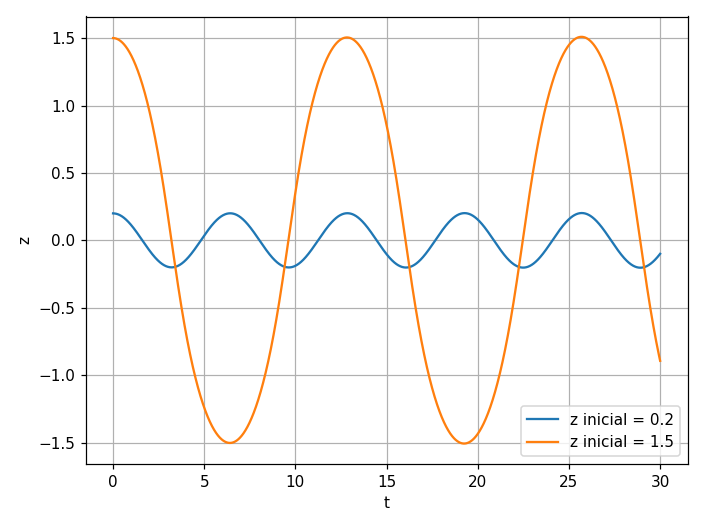

In [12]:
plt.figure()
plt.plot(t1, z1, label="z inicial = 0.2")
plt.plot(t2, z2, label="z inicial = 1.5")
plt.xlabel("t")
plt.ylabel("z")
plt.legend()
plt.grid()
plt.show()

### Variación de la energía total

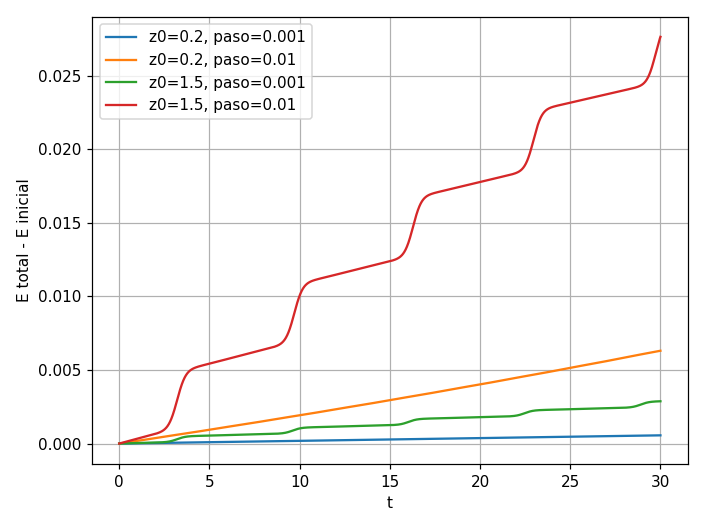

In [13]:
plt.figure()
for t, E, etiqueta in [(t1, E1, "z0=0.2, paso=0.001"),
                       (t1b, E1b, "z0=0.2, paso=0.01"),
                       (t2, E2, "z0=1.5, paso=0.001"),
                       (t2b, E2b, "z0=1.5, paso=0.01")]:
    plt.plot(t, [energia-E[0] for energia in E], label=etiqueta)
plt.xlabel("t")
plt.ylabel("E total - E inicial")
plt.legend()
plt.grid()
plt.show()

### Trayectoria fuera del eje

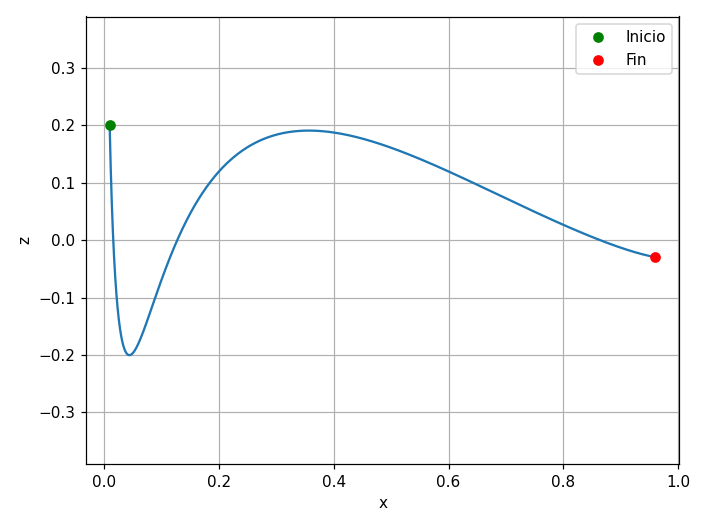

In [14]:
plt.figure()
plt.plot([p[0] for p in pos4], [p[2] for p in pos4])
plt.plot(pos4[0][0], pos4[0][2], "go", label="Inicio")
plt.plot(pos4[-1][0], pos4[-1][2], "ro", label="Fin")
plt.xlabel("x")
plt.ylabel("z")
plt.axis("equal")
plt.legend()
plt.grid()
plt.show()

## 3. Dispersión de una carga positiva

**3.1.** Lanzamiento desde (0, 0, -4), con velocidades 1.2 y 1.3, hasta t = 10.

In [15]:
for v0 in [1.2, 1.3]:
    t, pos, K, U, rf, tf = simular(1, np.array([0, 0, -4]), np.array([0, 0, v0]), 10, 1e-3,
                                   en_eje=True, titulo="desde (0,0,-4), v0 = " + str(v0))
    z_maximo = max([p[2] for p in pos])
    print("v0 =", v0, "| z maximo =", round(z_maximo, 3), "| z final =", round(rf[2], 3))

v0 = 1.2 | z maximo = -0.28 | z final = -3.755
v0 = 1.3 | z maximo = 5.869 | z final = 5.869


Ver escena 3D: desde (0,0,-4), v0 = 1.2 <iframe width="720" height="1020" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<style>body{font:14px sans-serif;margin:8px}button{padding:6px 14px}#estado{margin:8px 0}</style>
</head><body>
<button id="inicio">Iniciar</button><div id="estado"></div>
<div id="glowscript" class="glowscript"></div>
<script>
const datos = {"titulo": "desde (0,0,-4), v0 = 1.2", "anillo": [[1.0, 0.0, 0.0], [0.9945218953682733, 0.10452846326765346, 0.0], [0.9781476007338057, 0.20791169081775931, 0.0], [0.9510565162951535, 0.3090169943749474, 0.0], [0.9135454576426009, 0.40673664307580015, 0.0], [0.8660254037844387, 0.49999999999999994, 0.0], [0.8090169943749475, 0.5877852522924731, 0.0], [0.7431448254773942, 0.6691306063588582, 0.0], [0.6691306063588582, 0.7431448254773941, 0.0], [0.5877852522924731, 0.8090169943749475, 0.0], [0.5000000000000001, 0.8660254037844386, 0.0], [0.4067366430758004, 0.9135454576426009, 0.0], [0.30901699437494745, 0.9510565162951535, 0.0], [0.20791169081775923, 0.9781476007338057, 0.0], [0.10452846326765346, 0.9945218953682733, 0.0], [2.83276944882399e-16, 1.0, 0.0], [-0.10452846326765333, 0.9945218953682734, 0.0], [-0.20791169081775934, 0.9781476007338057, 0.0], [-0.30901699437494734, 0.9510565162951536, 0.0], [-0.40673664307580004, 0.913545457642601, 0.0], [-0.4999999999999998, 0.8660254037844387, 0.0], [-0.587785252292473, 0.8090169943749475, 0.0], [-0.6691306063588579, 0.7431448254773945, 0.0], [-0.743144825477394, 0.6691306063588583, 0.0], [-0.8090169943749473, 0.5877852522924732, 0.0], [-0.8660254037844387, 0.49999999999999994, 0.0], [-0.913545457642601, 0.40673664307580004, 0.0], [-0.9510565162951535, 0.3090169943749475, 0.0], [-0.9781476007338057, 0.20791169081775931, 0.0], [-0.9945218953682734, 0.10452846326765329, 0.0], [-1.0, 5.66553889764798e-16, 0.0], [-0.9945218953682734, -0.10452846326765305, 0.0], [-0.9781476007338057, -0.20791169081775907, 0.0], [-0.9510565162951536, -0.3090169943749473, 0.0], [-0.9135454576426009, -0.4067366430758002, 0.0], [-0.8660254037844388, -0.4999999999999997, 0.0], [-0.8090169943749476, -0.587785252292473, 0.0], [-0.7431448254773942, -0.6691306063588582, 0.0], [-0.6691306063588585, -0.743144825477394, 0.0], [-0.5877852522924732, -0.8090169943749473, 0.0], [-0.5000000000000004, -0.8660254037844384, 0.0], [-0.4067366430758009, -0.9135454576426005, 0.0], [-0.30901699437494756, -0.9510565162951535, 0.0], [-0.2079116908177598, -0.9781476007338056, 0.0], [-0.10452846326765423, -0.9945218953682733, 0.0], [-1.8369701987210297e-16, -1.0, 0.0], [0.10452846326765299, -0.9945218953682734, 0.0], [0.20791169081775943, -0.9781476007338056, 0.0], [0.30901699437494723, -0.9510565162951536, 0.0], [0.40673664307579976, -0.9135454576426011, 0.0], [0.5000000000000001, -0.8660254037844386, 0.0], [0.5877852522924729, -0.8090169943749476, 0.0], [0.6691306063588585, -0.743144825477394, 0.0], [0.7431448254773942, -0.6691306063588581, 0.0], [0.8090169943749473, -0.5877852522924734, 0.0], [0.8660254037844388, -0.49999999999999967, 0.0], [0.913545457642601, -0.40673664307580015, 0.0], [0.9510565162951535, -0.3090169943749476, 0.0], [0.9781476007338057, -0.20791169081775898, 0.0], [0.9945218953682733, -0.10452846326765342, 0.0]], "flechas": [[[-2.0, 0.0, -2.0], [-0.1912947624869286, -4.3450690439143765e-18, -0.23109806110192613]], [[-2.0, 0.0, -1.6], [-0.21104178955260955, -7.625747254305829e-18, -0.21321670446386717]], [[-2.0, 0.0, -1.2], [-0.23431936188465688, -4.317784066310772e-18, -0.18733509187006894]], [[-2.0, 0.0, -0.8], [-0.26117069052978487, -1.130424305057837e-17, -0.14761392349028368]], [[-2.0, 0.0, -0.4], [-0.2875630773746028, -3.9949483844186105e-18, -0.08548377934349988]], [[-2.0, 0.0, -0.0], [-0.3, -1.0298705721115019e-17, 0.0]], [[-2.0, 0.0, 0.4], [-0.2875630773746028, -3.9949483844186105e-18, 0.08548377934349988]], [[-2.0, 0.0, 0.8], [-0.26117069052978487, -1.130424305057837e-17, 0.14761392349028368]], [[-2.0, 0.0, 1.2], [-0.

Ver escena 3D: desde (0,0,-4), v0 = 1.3 <iframe width="720" height="1020" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<style>body{font:14px sans-serif;margin:8px}button{padding:6px 14px}#estado{margin:8px 0}</style>
</head><body>
<button id="inicio">Iniciar</button><div id="estado"></div>
<div id="glowscript" class="glowscript"></div>
<script>
const datos = {"titulo": "desde (0,0,-4), v0 = 1.3", "anillo": [[1.0, 0.0, 0.0], [0.9945218953682733, 0.10452846326765346, 0.0], [0.9781476007338057, 0.20791169081775931, 0.0], [0.9510565162951535, 0.3090169943749474, 0.0], [0.9135454576426009, 0.40673664307580015, 0.0], [0.8660254037844387, 0.49999999999999994, 0.0], [0.8090169943749475, 0.5877852522924731, 0.0], [0.7431448254773942, 0.6691306063588582, 0.0], [0.6691306063588582, 0.7431448254773941, 0.0], [0.5877852522924731, 0.8090169943749475, 0.0], [0.5000000000000001, 0.8660254037844386, 0.0], [0.4067366430758004, 0.9135454576426009, 0.0], [0.30901699437494745, 0.9510565162951535, 0.0], [0.20791169081775923, 0.9781476007338057, 0.0], [0.10452846326765346, 0.9945218953682733, 0.0], [2.83276944882399e-16, 1.0, 0.0], [-0.10452846326765333, 0.9945218953682734, 0.0], [-0.20791169081775934, 0.9781476007338057, 0.0], [-0.30901699437494734, 0.9510565162951536, 0.0], [-0.40673664307580004, 0.913545457642601, 0.0], [-0.4999999999999998, 0.8660254037844387, 0.0], [-0.587785252292473, 0.8090169943749475, 0.0], [-0.6691306063588579, 0.7431448254773945, 0.0], [-0.743144825477394, 0.6691306063588583, 0.0], [-0.8090169943749473, 0.5877852522924732, 0.0], [-0.8660254037844387, 0.49999999999999994, 0.0], [-0.913545457642601, 0.40673664307580004, 0.0], [-0.9510565162951535, 0.3090169943749475, 0.0], [-0.9781476007338057, 0.20791169081775931, 0.0], [-0.9945218953682734, 0.10452846326765329, 0.0], [-1.0, 5.66553889764798e-16, 0.0], [-0.9945218953682734, -0.10452846326765305, 0.0], [-0.9781476007338057, -0.20791169081775907, 0.0], [-0.9510565162951536, -0.3090169943749473, 0.0], [-0.9135454576426009, -0.4067366430758002, 0.0], [-0.8660254037844388, -0.4999999999999997, 0.0], [-0.8090169943749476, -0.587785252292473, 0.0], [-0.7431448254773942, -0.6691306063588582, 0.0], [-0.6691306063588585, -0.743144825477394, 0.0], [-0.5877852522924732, -0.8090169943749473, 0.0], [-0.5000000000000004, -0.8660254037844384, 0.0], [-0.4067366430758009, -0.9135454576426005, 0.0], [-0.30901699437494756, -0.9510565162951535, 0.0], [-0.2079116908177598, -0.9781476007338056, 0.0], [-0.10452846326765423, -0.9945218953682733, 0.0], [-1.8369701987210297e-16, -1.0, 0.0], [0.10452846326765299, -0.9945218953682734, 0.0], [0.20791169081775943, -0.9781476007338056, 0.0], [0.30901699437494723, -0.9510565162951536, 0.0], [0.40673664307579976, -0.9135454576426011, 0.0], [0.5000000000000001, -0.8660254037844386, 0.0], [0.5877852522924729, -0.8090169943749476, 0.0], [0.6691306063588585, -0.743144825477394, 0.0], [0.7431448254773942, -0.6691306063588581, 0.0], [0.8090169943749473, -0.5877852522924734, 0.0], [0.8660254037844388, -0.49999999999999967, 0.0], [0.913545457642601, -0.40673664307580015, 0.0], [0.9510565162951535, -0.3090169943749476, 0.0], [0.9781476007338057, -0.20791169081775898, 0.0], [0.9945218953682733, -0.10452846326765342, 0.0]], "flechas": [[[-2.0, 0.0, -2.0], [-0.1912947624869286, -4.3450690439143765e-18, -0.23109806110192613]], [[-2.0, 0.0, -1.6], [-0.21104178955260955, -7.625747254305829e-18, -0.21321670446386717]], [[-2.0, 0.0, -1.2], [-0.23431936188465688, -4.317784066310772e-18, -0.18733509187006894]], [[-2.0, 0.0, -0.8], [-0.26117069052978487, -1.130424305057837e-17, -0.14761392349028368]], [[-2.0, 0.0, -0.4], [-0.2875630773746028, -3.9949483844186105e-18, -0.08548377934349988]], [[-2.0, 0.0, -0.0], [-0.3, -1.0298705721115019e-17, 0.0]], [[-2.0, 0.0, 0.4], [-0.2875630773746028, -3.9949483844186105e-18, 0.08548377934349988]], [[-2.0, 0.0, 0.8], [-0.26117069052978487, -1.130424305057837e-17, 0.14761392349028368]], [[-2.0, 0.0, 1.2], [-0.

**3.2.** Mismas velocidades, ahora desde (0.5, 0, -4).

In [16]:
for v0 in [1.2, 1.3]:
    t, pos, K, U, rf, tf = simular(1, np.array([0.5, 0, -4]), np.array([0, 0, v0]), 10, 1e-3,
                                   titulo="desde (0.5,0,-4), v0 = " + str(v0))
    z_maximo = max([p[2] for p in pos])
    print("v0 =", v0, "| z maximo =", round(z_maximo, 3), "| posicion final:", round(rf[0], 3), round(rf[1], 3) + 0.0, round(rf[2], 3))

v0 = 1.2 | z maximo = -0.435 | posicion final: 2.859 0.0 -5.549
v0 = 1.3 | z maximo = -0.207 | posicion final: -1.323 0.0 -5.354


Ver escena 3D: desde (0.5,0,-4), v0 = 1.2 <iframe width="720" height="1020" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<style>body{font:14px sans-serif;margin:8px}button{padding:6px 14px}#estado{margin:8px 0}</style>
</head><body>
<button id="inicio">Iniciar</button><div id="estado"></div>
<div id="glowscript" class="glowscript"></div>
<script>
const datos = {"titulo": "desde (0.5,0,-4), v0 = 1.2", "anillo": [[1.0, 0.0, 0.0], [0.9945218953682733, 0.10452846326765346, 0.0], [0.9781476007338057, 0.20791169081775931, 0.0], [0.9510565162951535, 0.3090169943749474, 0.0], [0.9135454576426009, 0.40673664307580015, 0.0], [0.8660254037844387, 0.49999999999999994, 0.0], [0.8090169943749475, 0.5877852522924731, 0.0], [0.7431448254773942, 0.6691306063588582, 0.0], [0.6691306063588582, 0.7431448254773941, 0.0], [0.5877852522924731, 0.8090169943749475, 0.0], [0.5000000000000001, 0.8660254037844386, 0.0], [0.4067366430758004, 0.9135454576426009, 0.0], [0.30901699437494745, 0.9510565162951535, 0.0], [0.20791169081775923, 0.9781476007338057, 0.0], [0.10452846326765346, 0.9945218953682733, 0.0], [2.83276944882399e-16, 1.0, 0.0], [-0.10452846326765333, 0.9945218953682734, 0.0], [-0.20791169081775934, 0.9781476007338057, 0.0], [-0.30901699437494734, 0.9510565162951536, 0.0], [-0.40673664307580004, 0.913545457642601, 0.0], [-0.4999999999999998, 0.8660254037844387, 0.0], [-0.587785252292473, 0.8090169943749475, 0.0], [-0.6691306063588579, 0.7431448254773945, 0.0], [-0.743144825477394, 0.6691306063588583, 0.0], [-0.8090169943749473, 0.5877852522924732, 0.0], [-0.8660254037844387, 0.49999999999999994, 0.0], [-0.913545457642601, 0.40673664307580004, 0.0], [-0.9510565162951535, 0.3090169943749475, 0.0], [-0.9781476007338057, 0.20791169081775931, 0.0], [-0.9945218953682734, 0.10452846326765329, 0.0], [-1.0, 5.66553889764798e-16, 0.0], [-0.9945218953682734, -0.10452846326765305, 0.0], [-0.9781476007338057, -0.20791169081775907, 0.0], [-0.9510565162951536, -0.3090169943749473, 0.0], [-0.9135454576426009, -0.4067366430758002, 0.0], [-0.8660254037844388, -0.4999999999999997, 0.0], [-0.8090169943749476, -0.587785252292473, 0.0], [-0.7431448254773942, -0.6691306063588582, 0.0], [-0.6691306063588585, -0.743144825477394, 0.0], [-0.5877852522924732, -0.8090169943749473, 0.0], [-0.5000000000000004, -0.8660254037844384, 0.0], [-0.4067366430758009, -0.9135454576426005, 0.0], [-0.30901699437494756, -0.9510565162951535, 0.0], [-0.2079116908177598, -0.9781476007338056, 0.0], [-0.10452846326765423, -0.9945218953682733, 0.0], [-1.8369701987210297e-16, -1.0, 0.0], [0.10452846326765299, -0.9945218953682734, 0.0], [0.20791169081775943, -0.9781476007338056, 0.0], [0.30901699437494723, -0.9510565162951536, 0.0], [0.40673664307579976, -0.9135454576426011, 0.0], [0.5000000000000001, -0.8660254037844386, 0.0], [0.5877852522924729, -0.8090169943749476, 0.0], [0.6691306063588585, -0.743144825477394, 0.0], [0.7431448254773942, -0.6691306063588581, 0.0], [0.8090169943749473, -0.5877852522924734, 0.0], [0.8660254037844388, -0.49999999999999967, 0.0], [0.913545457642601, -0.40673664307580015, 0.0], [0.9510565162951535, -0.3090169943749476, 0.0], [0.9781476007338057, -0.20791169081775898, 0.0], [0.9945218953682733, -0.10452846326765342, 0.0]], "flechas": [[[-2.0, 0.0, -2.0], [-0.1912947624869286, -4.3450690439143765e-18, -0.23109806110192613]], [[-2.0, 0.0, -1.6], [-0.21104178955260955, -7.625747254305829e-18, -0.21321670446386717]], [[-2.0, 0.0, -1.2], [-0.23431936188465688, -4.317784066310772e-18, -0.18733509187006894]], [[-2.0, 0.0, -0.8], [-0.26117069052978487, -1.130424305057837e-17, -0.14761392349028368]], [[-2.0, 0.0, -0.4], [-0.2875630773746028, -3.9949483844186105e-18, -0.08548377934349988]], [[-2.0, 0.0, -0.0], [-0.3, -1.0298705721115019e-17, 0.0]], [[-2.0, 0.0, 0.4], [-0.2875630773746028, -3.9949483844186105e-18, 0.08548377934349988]], [[-2.0, 0.0, 0.8], [-0.26117069052978487, -1.130424305057837e-17, 0.14761392349028368]], [[-2.0, 0.0, 1.2], 

Ver escena 3D: desde (0.5,0,-4), v0 = 1.3 <iframe width="720" height="1020" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<style>body{font:14px sans-serif;margin:8px}button{padding:6px 14px}#estado{margin:8px 0}</style>
</head><body>
<button id="inicio">Iniciar</button><div id="estado"></div>
<div id="glowscript" class="glowscript"></div>
<script>
const datos = {"titulo": "desde (0.5,0,-4), v0 = 1.3", "anillo": [[1.0, 0.0, 0.0], [0.9945218953682733, 0.10452846326765346, 0.0], [0.9781476007338057, 0.20791169081775931, 0.0], [0.9510565162951535, 0.3090169943749474, 0.0], [0.9135454576426009, 0.40673664307580015, 0.0], [0.8660254037844387, 0.49999999999999994, 0.0], [0.8090169943749475, 0.5877852522924731, 0.0], [0.7431448254773942, 0.6691306063588582, 0.0], [0.6691306063588582, 0.7431448254773941, 0.0], [0.5877852522924731, 0.8090169943749475, 0.0], [0.5000000000000001, 0.8660254037844386, 0.0], [0.4067366430758004, 0.9135454576426009, 0.0], [0.30901699437494745, 0.9510565162951535, 0.0], [0.20791169081775923, 0.9781476007338057, 0.0], [0.10452846326765346, 0.9945218953682733, 0.0], [2.83276944882399e-16, 1.0, 0.0], [-0.10452846326765333, 0.9945218953682734, 0.0], [-0.20791169081775934, 0.9781476007338057, 0.0], [-0.30901699437494734, 0.9510565162951536, 0.0], [-0.40673664307580004, 0.913545457642601, 0.0], [-0.4999999999999998, 0.8660254037844387, 0.0], [-0.587785252292473, 0.8090169943749475, 0.0], [-0.6691306063588579, 0.7431448254773945, 0.0], [-0.743144825477394, 0.6691306063588583, 0.0], [-0.8090169943749473, 0.5877852522924732, 0.0], [-0.8660254037844387, 0.49999999999999994, 0.0], [-0.913545457642601, 0.40673664307580004, 0.0], [-0.9510565162951535, 0.3090169943749475, 0.0], [-0.9781476007338057, 0.20791169081775931, 0.0], [-0.9945218953682734, 0.10452846326765329, 0.0], [-1.0, 5.66553889764798e-16, 0.0], [-0.9945218953682734, -0.10452846326765305, 0.0], [-0.9781476007338057, -0.20791169081775907, 0.0], [-0.9510565162951536, -0.3090169943749473, 0.0], [-0.9135454576426009, -0.4067366430758002, 0.0], [-0.8660254037844388, -0.4999999999999997, 0.0], [-0.8090169943749476, -0.587785252292473, 0.0], [-0.7431448254773942, -0.6691306063588582, 0.0], [-0.6691306063588585, -0.743144825477394, 0.0], [-0.5877852522924732, -0.8090169943749473, 0.0], [-0.5000000000000004, -0.8660254037844384, 0.0], [-0.4067366430758009, -0.9135454576426005, 0.0], [-0.30901699437494756, -0.9510565162951535, 0.0], [-0.2079116908177598, -0.9781476007338056, 0.0], [-0.10452846326765423, -0.9945218953682733, 0.0], [-1.8369701987210297e-16, -1.0, 0.0], [0.10452846326765299, -0.9945218953682734, 0.0], [0.20791169081775943, -0.9781476007338056, 0.0], [0.30901699437494723, -0.9510565162951536, 0.0], [0.40673664307579976, -0.9135454576426011, 0.0], [0.5000000000000001, -0.8660254037844386, 0.0], [0.5877852522924729, -0.8090169943749476, 0.0], [0.6691306063588585, -0.743144825477394, 0.0], [0.7431448254773942, -0.6691306063588581, 0.0], [0.8090169943749473, -0.5877852522924734, 0.0], [0.8660254037844388, -0.49999999999999967, 0.0], [0.913545457642601, -0.40673664307580015, 0.0], [0.9510565162951535, -0.3090169943749476, 0.0], [0.9781476007338057, -0.20791169081775898, 0.0], [0.9945218953682733, -0.10452846326765342, 0.0]], "flechas": [[[-2.0, 0.0, -2.0], [-0.1912947624869286, -4.3450690439143765e-18, -0.23109806110192613]], [[-2.0, 0.0, -1.6], [-0.21104178955260955, -7.625747254305829e-18, -0.21321670446386717]], [[-2.0, 0.0, -1.2], [-0.23431936188465688, -4.317784066310772e-18, -0.18733509187006894]], [[-2.0, 0.0, -0.8], [-0.26117069052978487, -1.130424305057837e-17, -0.14761392349028368]], [[-2.0, 0.0, -0.4], [-0.2875630773746028, -3.9949483844186105e-18, -0.08548377934349988]], [[-2.0, 0.0, -0.0], [-0.3, -1.0298705721115019e-17, 0.0]], [[-2.0, 0.0, 0.4], [-0.2875630773746028, -3.9949483844186105e-18, 0.08548377934349988]], [[-2.0, 0.0, 0.8], [-0.26117069052978487, -1.130424305057837e-17, 0.14761392349028368]], [[-2.0, 0.0, 1.2], 

**3.3.** Desde (0.5, 0, -4), con velocidades (0, 0.1, 1.2) y (0, 0.1, 1.5).

In [17]:
for vz in [1.2, 1.5]:
    t, pos, K, U, rf, tf = simular(1, np.array([0.5, 0, -4]), np.array([0, 0.1, vz]), 10, 1e-3,
                                   titulo="desde (0.5,0,-4), v0 = (0,0.1," + str(vz) + ")")
    z_maximo = max([p[2] for p in pos])
    print("vz =", vz, "| z maximo =", round(z_maximo, 3), "| posicion final:", round(rf[0], 3), round(rf[1], 3) + 0.0, round(rf[2], 3))

vz = 1.2 | z maximo = -0.454 | posicion final: 4.173 3.41 -4.571
vz = 1.5 | z maximo = 9.059 | posicion final: -1.385 -0.175 9.059


Ver escena 3D: desde (0.5,0,-4), v0 = (0,0.1,1.2) <iframe width="720" height="1020" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<style>body{font:14px sans-serif;margin:8px}button{padding:6px 14px}#estado{margin:8px 0}</style>
</head><body>
<button id="inicio">Iniciar</button><div id="estado"></div>
<div id="glowscript" class="glowscript"></div>
<script>
const datos = {"titulo": "desde (0.5,0,-4), v0 = (0,0.1,1.2)", "anillo": [[1.0, 0.0, 0.0], [0.9945218953682733, 0.10452846326765346, 0.0], [0.9781476007338057, 0.20791169081775931, 0.0], [0.9510565162951535, 0.3090169943749474, 0.0], [0.9135454576426009, 0.40673664307580015, 0.0], [0.8660254037844387, 0.49999999999999994, 0.0], [0.8090169943749475, 0.5877852522924731, 0.0], [0.7431448254773942, 0.6691306063588582, 0.0], [0.6691306063588582, 0.7431448254773941, 0.0], [0.5877852522924731, 0.8090169943749475, 0.0], [0.5000000000000001, 0.8660254037844386, 0.0], [0.4067366430758004, 0.9135454576426009, 0.0], [0.30901699437494745, 0.9510565162951535, 0.0], [0.20791169081775923, 0.9781476007338057, 0.0], [0.10452846326765346, 0.9945218953682733, 0.0], [2.83276944882399e-16, 1.0, 0.0], [-0.10452846326765333, 0.9945218953682734, 0.0], [-0.20791169081775934, 0.9781476007338057, 0.0], [-0.30901699437494734, 0.9510565162951536, 0.0], [-0.40673664307580004, 0.913545457642601, 0.0], [-0.4999999999999998, 0.8660254037844387, 0.0], [-0.587785252292473, 0.8090169943749475, 0.0], [-0.6691306063588579, 0.7431448254773945, 0.0], [-0.743144825477394, 0.6691306063588583, 0.0], [-0.8090169943749473, 0.5877852522924732, 0.0], [-0.8660254037844387, 0.49999999999999994, 0.0], [-0.913545457642601, 0.40673664307580004, 0.0], [-0.9510565162951535, 0.3090169943749475, 0.0], [-0.9781476007338057, 0.20791169081775931, 0.0], [-0.9945218953682734, 0.10452846326765329, 0.0], [-1.0, 5.66553889764798e-16, 0.0], [-0.9945218953682734, -0.10452846326765305, 0.0], [-0.9781476007338057, -0.20791169081775907, 0.0], [-0.9510565162951536, -0.3090169943749473, 0.0], [-0.9135454576426009, -0.4067366430758002, 0.0], [-0.8660254037844388, -0.4999999999999997, 0.0], [-0.8090169943749476, -0.587785252292473, 0.0], [-0.7431448254773942, -0.6691306063588582, 0.0], [-0.6691306063588585, -0.743144825477394, 0.0], [-0.5877852522924732, -0.8090169943749473, 0.0], [-0.5000000000000004, -0.8660254037844384, 0.0], [-0.4067366430758009, -0.9135454576426005, 0.0], [-0.30901699437494756, -0.9510565162951535, 0.0], [-0.2079116908177598, -0.9781476007338056, 0.0], [-0.10452846326765423, -0.9945218953682733, 0.0], [-1.8369701987210297e-16, -1.0, 0.0], [0.10452846326765299, -0.9945218953682734, 0.0], [0.20791169081775943, -0.9781476007338056, 0.0], [0.30901699437494723, -0.9510565162951536, 0.0], [0.40673664307579976, -0.9135454576426011, 0.0], [0.5000000000000001, -0.8660254037844386, 0.0], [0.5877852522924729, -0.8090169943749476, 0.0], [0.6691306063588585, -0.743144825477394, 0.0], [0.7431448254773942, -0.6691306063588581, 0.0], [0.8090169943749473, -0.5877852522924734, 0.0], [0.8660254037844388, -0.49999999999999967, 0.0], [0.913545457642601, -0.40673664307580015, 0.0], [0.9510565162951535, -0.3090169943749476, 0.0], [0.9781476007338057, -0.20791169081775898, 0.0], [0.9945218953682733, -0.10452846326765342, 0.0]], "flechas": [[[-2.0, 0.0, -2.0], [-0.1912947624869286, -4.3450690439143765e-18, -0.23109806110192613]], [[-2.0, 0.0, -1.6], [-0.21104178955260955, -7.625747254305829e-18, -0.21321670446386717]], [[-2.0, 0.0, -1.2], [-0.23431936188465688, -4.317784066310772e-18, -0.18733509187006894]], [[-2.0, 0.0, -0.8], [-0.26117069052978487, -1.130424305057837e-17, -0.14761392349028368]], [[-2.0, 0.0, -0.4], [-0.2875630773746028, -3.9949483844186105e-18, -0.08548377934349988]], [[-2.0, 0.0, -0.0], [-0.3, -1.0298705721115019e-17, 0.0]], [[-2.0, 0.0, 0.4], [-0.2875630773746028, -3.9949483844186105e-18, 0.08548377934349988]], [[-2.0, 0.0, 0.8], [-0.26117069052978487, -1.130424305057837e-17, 0.14761392349028368]], [[-

Ver escena 3D: desde (0.5,0,-4), v0 = (0,0.1,1.5) <iframe width="720" height="1020" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<style>body{font:14px sans-serif;margin:8px}button{padding:6px 14px}#estado{margin:8px 0}</style>
</head><body>
<button id="inicio">Iniciar</button><div id="estado"></div>
<div id="glowscript" class="glowscript"></div>
<script>
const datos = {"titulo": "desde (0.5,0,-4), v0 = (0,0.1,1.5)", "anillo": [[1.0, 0.0, 0.0], [0.9945218953682733, 0.10452846326765346, 0.0], [0.9781476007338057, 0.20791169081775931, 0.0], [0.9510565162951535, 0.3090169943749474, 0.0], [0.9135454576426009, 0.40673664307580015, 0.0], [0.8660254037844387, 0.49999999999999994, 0.0], [0.8090169943749475, 0.5877852522924731, 0.0], [0.7431448254773942, 0.6691306063588582, 0.0], [0.6691306063588582, 0.7431448254773941, 0.0], [0.5877852522924731, 0.8090169943749475, 0.0], [0.5000000000000001, 0.8660254037844386, 0.0], [0.4067366430758004, 0.9135454576426009, 0.0], [0.30901699437494745, 0.9510565162951535, 0.0], [0.20791169081775923, 0.9781476007338057, 0.0], [0.10452846326765346, 0.9945218953682733, 0.0], [2.83276944882399e-16, 1.0, 0.0], [-0.10452846326765333, 0.9945218953682734, 0.0], [-0.20791169081775934, 0.9781476007338057, 0.0], [-0.30901699437494734, 0.9510565162951536, 0.0], [-0.40673664307580004, 0.913545457642601, 0.0], [-0.4999999999999998, 0.8660254037844387, 0.0], [-0.587785252292473, 0.8090169943749475, 0.0], [-0.6691306063588579, 0.7431448254773945, 0.0], [-0.743144825477394, 0.6691306063588583, 0.0], [-0.8090169943749473, 0.5877852522924732, 0.0], [-0.8660254037844387, 0.49999999999999994, 0.0], [-0.913545457642601, 0.40673664307580004, 0.0], [-0.9510565162951535, 0.3090169943749475, 0.0], [-0.9781476007338057, 0.20791169081775931, 0.0], [-0.9945218953682734, 0.10452846326765329, 0.0], [-1.0, 5.66553889764798e-16, 0.0], [-0.9945218953682734, -0.10452846326765305, 0.0], [-0.9781476007338057, -0.20791169081775907, 0.0], [-0.9510565162951536, -0.3090169943749473, 0.0], [-0.9135454576426009, -0.4067366430758002, 0.0], [-0.8660254037844388, -0.4999999999999997, 0.0], [-0.8090169943749476, -0.587785252292473, 0.0], [-0.7431448254773942, -0.6691306063588582, 0.0], [-0.6691306063588585, -0.743144825477394, 0.0], [-0.5877852522924732, -0.8090169943749473, 0.0], [-0.5000000000000004, -0.8660254037844384, 0.0], [-0.4067366430758009, -0.9135454576426005, 0.0], [-0.30901699437494756, -0.9510565162951535, 0.0], [-0.2079116908177598, -0.9781476007338056, 0.0], [-0.10452846326765423, -0.9945218953682733, 0.0], [-1.8369701987210297e-16, -1.0, 0.0], [0.10452846326765299, -0.9945218953682734, 0.0], [0.20791169081775943, -0.9781476007338056, 0.0], [0.30901699437494723, -0.9510565162951536, 0.0], [0.40673664307579976, -0.9135454576426011, 0.0], [0.5000000000000001, -0.8660254037844386, 0.0], [0.5877852522924729, -0.8090169943749476, 0.0], [0.6691306063588585, -0.743144825477394, 0.0], [0.7431448254773942, -0.6691306063588581, 0.0], [0.8090169943749473, -0.5877852522924734, 0.0], [0.8660254037844388, -0.49999999999999967, 0.0], [0.913545457642601, -0.40673664307580015, 0.0], [0.9510565162951535, -0.3090169943749476, 0.0], [0.9781476007338057, -0.20791169081775898, 0.0], [0.9945218953682733, -0.10452846326765342, 0.0]], "flechas": [[[-2.0, 0.0, -2.0], [-0.1912947624869286, -4.3450690439143765e-18, -0.23109806110192613]], [[-2.0, 0.0, -1.6], [-0.21104178955260955, -7.625747254305829e-18, -0.21321670446386717]], [[-2.0, 0.0, -1.2], [-0.23431936188465688, -4.317784066310772e-18, -0.18733509187006894]], [[-2.0, 0.0, -0.8], [-0.26117069052978487, -1.130424305057837e-17, -0.14761392349028368]], [[-2.0, 0.0, -0.4], [-0.2875630773746028, -3.9949483844186105e-18, -0.08548377934349988]], [[-2.0, 0.0, -0.0], [-0.3, -1.0298705721115019e-17, 0.0]], [[-2.0, 0.0, 0.4], [-0.2875630773746028, -3.9949483844186105e-18, 0.08548377934349988]], [[-2.0, 0.0, 0.8], [-0.26117069052978487, -1.130424305057837e-17, 0.14761392349028368]], [[-

**3.4.** Componentes del campo sobre el eje y fuera de él.

In [18]:
print("   x       z          Ex          Ey          Ez")
for z in [-0.5, -0.25]:
    for x in [0, 0.5]:
        E = campo_E(np.array([x, 0, z]))
        print(f"{x:5.1f}   {z:6.2f}   {E[0]+0.0:10.4f}  {abs(E[1]):10.4f}  {E[2]:10.4f}")

   x       z          Ex          Ey          Ez
  0.0    -0.50       0.0000      0.0000     -0.3578
  0.5    -0.50      -0.0402      0.0000     -0.4745
  0.0    -0.25       0.0000      0.0000     -0.2283
  0.5    -0.25      -0.2122      0.0000     -0.3792


**a.** Usamos conservación de la energía para la partícula y su interacción con el anillo fijo. Tomamos $U=qV$, con potencial cero en el infinito. La mayor energía potencial sobre el eje está en z = 0:

$$\frac12mv_0^2+qV(z_i)=\frac12mv_f^2+qV(0).$$

En el caso límite, la velocidad en el centro tiende a cero. Despejando antes de sustituir:

$$v_{\min}=\sqrt{\frac{2kQq}{m}
\left(\frac1R-\frac1{\sqrt{R^2+z_i^2}}\right)}.$$

Con $z_i=-4$ y los demás parámetros iguales a 1:

$$v_{\min}=\sqrt{2\left(1-\frac1{\sqrt{17}}\right)}\approx1.231.$$

Esto coincide con la simulación: con 1.2 la partícula se devuelve, mientras que con 1.3 atraviesa el anillo. Para cruzar debe superar el valor límite; si fuera exactamente igual, se acercaría al centro cada vez más despacio sin pasarlo en un tiempo finito.

**b.** En los puntos de la tabla, $E_z$ es negativo y su magnitud es mayor fuera del eje. Por ejemplo, en z = -0.25 pasa de -0.2283 en x = 0 a -0.3792 en x = 0.5. La carga positiva recibe una fuerza hacia z negativo que frena su avance.

También aparece una fuerza lateral, de modo que parte de la energía cinética queda en el movimiento en x. La rapidez mínima calculada para el eje no determina lo que ocurre en esta trayectoria. Con velocidad inicial 1.3, la partícula solo llega hasta z aproximado -0.207 y se devuelve.

En (0.5, 0, -0.25), $E_x=-0.2122$: apunta hacia x negativo, hacia el eje desde ese punto. Por eso desvía la carga positiva en esa dirección.

**c.** En el plano y = 0 se cancelan las componentes del campo en y, así que $F_y=0$. En los puntos 1 y 2 la partícula empieza en ese plano con velocidad en y igual a cero y permanece allí. Sobre el eje también se cancela $F_x$, de modo que en el punto 1 el movimiento es solo en z. Por la misma simetría, $F_x=0$ en el plano x = 0.

En el punto 3 la velocidad inicial en y vale 0.1. La partícula sale del plano y = 0, donde ya no está garantizada la cancelación de $F_y$, y la trayectoria se desarrolla en las tres dimensiones.